In [1]:
import pandas as pd

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.preprocessing import LabelEncoder

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
from google.colab import files
uploaded = files.upload()

Saving dataset_tugas1_preprocessing.csv to dataset_tugas1_preprocessing.csv


In [6]:
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

In [7]:
df_asli = df.copy()

In [8]:
print("Dataset berhasil dibaca.")
display(df.head())

Dataset berhasil dibaca.


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [9]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (99, 8)


In [10]:
print("\nStruktur dan tipe data:")
df.info()


Struktur dan tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB


In [11]:
print("\nJumlah missing values per kolom:")
print(df.isnull().sum())


Jumlah missing values per kolom:
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64


In [12]:
print("\nStatistik deskriptif:")
display(df.describe(include='all'))


Statistik deskriptif:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
count,99,99,99,99,99,70,99,90.000000
unique,99,10,2,4,4,5,97,NaN
top,MH001,Eka,Laki-laki,Teknik Komputer,Cuti,C,2020/03/31,NaN
freq,1,15,50,28,29,17,2,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.366667
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.763963
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.000000


In [13]:
modus_nilai = df['Nilai_Akhir'].mode()[0]
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(modus_nilai)

In [14]:
df['Umur'] = pd.to_numeric(df['Umur'], errors='coerce')
median_umur = df['Umur'].median()
df['Umur'] = df['Umur'].fillna(median_umur)

In [15]:
print("Missing values setelah imputasi:")
print(df[['Nilai_Akhir', 'Umur']].isnull().sum())

Missing values setelah imputasi:
Nilai_Akhir    0
Umur           0
dtype: int64


In [16]:
print("\nNilai modus Nilai_Akhir:", modus_nilai)
print("Nilai median Umur:", median_umur)


Nilai modus Nilai_Akhir: C
Nilai median Umur: 23.0


In [17]:
def konversi_tanggal(tanggal):
    if pd.isna(tanggal):
        return pd.NaT

    tanggal = str(tanggal).strip()

    if not tanggal:
        return pd.NaT

    if '-' in tanggal:
        return pd.to_datetime(
            tanggal,
            format='%d-%m-%Y',
            errors='coerce'
        )

    elif '/' in tanggal:
        return pd.to_datetime(
            tanggal,
            format='%m/%d/%Y',
            errors='coerce'
        )

    return pd.NaT

In [18]:
df['Tanggal_Ujian'] = df['Tanggal_Ujian'].apply(konversi_tanggal)

In [19]:
print("Tipe data tanggal:", df['Tanggal_Ujian'].dtype)
print("Tanggal yang tidak berhasil dikonversi:",
      df['Tanggal_Ujian'].isna().sum())

Tipe data tanggal: datetime64[ns]
Tanggal yang tidak berhasil dikonversi: 89


In [20]:
display(df[['ID', 'Tanggal_Ujian']].head(10))

,ID,Tanggal_Ujian
0,MH001,2020-04-13
1,MH002,NaT
2,MH003,NaT
3,MH004,NaT
4,MH005,NaT
5,MH006,NaT
6,MH007,NaT
7,MH008,NaT
8,MH009,NaT
9,MH010,NaT


In [21]:
print(df['Tanggal_Ujian'].head(15).to_string())
print(df['Tanggal_Ujian'].dtype)

0    2020-04-13
1           NaT
2           NaT
3           NaT
4           NaT
5           NaT
6           NaT
7           NaT
8           NaT
9           NaT
10   2020-10-10
11          NaT
12          NaT
13          NaT
14          NaT
datetime64[ns]


In [22]:
df = pd.read_csv(nama_file)

print(df['Tanggal_Ujian'].head(15).to_string())

NameError: name 'nama_file' is not defined

In [23]:
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

print(df['Tanggal_Ujian'].head(15).to_string())

0     13-04-2020
1     2020/12/11
2     2021/11/21
3     2021/08/19
4     2020/01/05
5     2021/10/15
6     2020/01/15
7     2020/09/16
8     2021/02/06
9     2020/02/12
10    10-10-2020
11    2022/12/02
12    2021/02/19
13    2020/06/17
14    2022/04/22


In [25]:
df = pd.read_csv('dataset_tugas1_preprocessing.csv')

print(df['Tanggal_Ujian'].head(15).to_string())

0     13-04-2020
1     2020/12/11
2     2021/11/21
3     2021/08/19
4     2020/01/05
5     2021/10/15
6     2020/01/15
7     2020/09/16
8     2021/02/06
9     2020/02/12
10    10-10-2020
11    2022/12/02
12    2021/02/19
13    2020/06/17
14    2022/04/22


In [27]:
def konversi_tanggal(tanggal):
    if pd.isna(tanggal):
        return pd.NaT

    tanggal = str(tanggal).strip()

    if not tanggal:
        return pd.NaT

    # Format DD-MM-YYYY, contoh 13-04-2020
    if '-' in tanggal:
        return pd.to_datetime(
            tanggal,
            format='%d-%m-%Y',
            errors='coerce'
        )

    # Format YYYY/MM/DD, contoh 2020/12/11
    if '/' in tanggal:
        return pd.to_datetime(
            tanggal,
            format='%Y/%m/%d',
            errors='coerce'
        )

    return pd.NaT


df['Tanggal_Ujian'] = df['Tanggal_Ujian'].apply(konversi_tanggal)

display(df[['ID', 'Tanggal_Ujian']].head(15))

,ID,Tanggal_Ujian
0,MH001,NaT
1,MH002,NaT
2,MH003,NaT
3,MH004,NaT
4,MH005,NaT
5,MH006,NaT
6,MH007,NaT
7,MH008,NaT
8,MH009,NaT
9,MH010,NaT


In [28]:
import pandas as pd

df = pd.read_csv('dataset_tugas1_preprocessing.csv')

print(df['Tanggal_Ujian'].head(15).to_string())

0     13-04-2020
1     2020/12/11
2     2021/11/21
3     2021/08/19
4     2020/01/05
5     2021/10/15
6     2020/01/15
7     2020/09/16
8     2021/02/06
9     2020/02/12
10    10-10-2020
11    2022/12/02
12    2021/02/19
13    2020/06/17
14    2022/04/22


In [29]:
def konversi_tanggal(tanggal):
    if pd.isna(tanggal):
        return pd.NaT

    tanggal = str(tanggal).strip()

    if '-' in tanggal:
        return pd.to_datetime(
            tanggal,
            format='%d-%m-%Y',
            errors='coerce'
        )

    elif '/' in tanggal:
        return pd.to_datetime(
            tanggal,
            format='%Y/%m/%d',
            errors='coerce'
        )

    return pd.NaT


df['Tanggal_Ujian'] = df['Tanggal_Ujian'].apply(konversi_tanggal)

display(df[['ID', 'Tanggal_Ujian']].head(15))

,ID,Tanggal_Ujian
0,MH001,2020-04-13
1,MH002,2020-12-11
2,MH003,2021-11-21
3,MH004,2021-08-19
4,MH005,2020-01-05
5,MH006,2021-10-15
6,MH007,2020-01-15
7,MH008,2020-09-16
8,MH009,2021-02-06
9,MH010,2020-02-12


In [30]:
print("Tipe data:", df['Tanggal_Ujian'].dtype)
print("Tanggal kosong:", df['Tanggal_Ujian'].isna().sum())

Tipe data: datetime64[ns]
Tanggal kosong: 0


In [31]:
kolom_kategorikal = [
    'Nama',
    'Jenis_Kelamin',
    'Prodi',
    'Status',
    'Nilai_Akhir'
]

encoders = {}

for kolom in kolom_kategorikal:
    encoder = LabelEncoder()
    df[kolom] = encoder.fit_transform(df[kolom].astype(str))
    encoders[kolom] = encoder

print("Hasil Label Encoding:")
display(df.head())

# Melihat pemetaan kategori menjadi angka
for kolom, encoder in encoders.items():
    print(f"\nPemetaan kategori {kolom}:")
    print(dict(zip(encoder.classes_,
                   encoder.transform(encoder.classes_))))

Hasil Label Encoding:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,5,2020-04-13,NaN
1,MH002,4,1,3,3,4,2020-12-11,28.0
2,MH003,8,0,3,0,5,2021-11-21,23.0
3,MH004,4,1,3,0,3,2021-08-19,18.0
4,MH005,9,1,0,0,2,2020-01-05,26.0



Pemetaan kategori Nama:
{'Adi': np.int64(0), 'Budi': np.int64(1), 'Citra': np.int64(2), 'Dina': np.int64(3), 'Eka': np.int64(4), 'Farhan': np.int64(5), 'Gita': np.int64(6), 'Hana': np.int64(7), 'Iwan': np.int64(8), 'Joko': np.int64(9)}

Pemetaan kategori Jenis_Kelamin:
{'Laki-laki': np.int64(0), 'Perempuan': np.int64(1)}

Pemetaan kategori Prodi:
{'Data Science': np.int64(0), 'Informatika': np.int64(1), 'Sistem Informasi': np.int64(2), 'Teknik Komputer': np.int64(3)}

Pemetaan kategori Status:
{'Aktif': np.int64(0), 'Cuti': np.int64(1), 'DO': np.int64(2), 'Lulus': np.int64(3)}

Pemetaan kategori Nilai_Akhir:
{'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2), 'D': np.int64(3), 'E': np.int64(4), 'nan': np.int64(5)}


In [32]:

# Mengubah Umur menjadi numerik
df['Umur'] = pd.to_numeric(df['Umur'], errors='coerce')

# Mengisi Umur yang kosong dengan median
median_umur = df['Umur'].median()
df['Umur'] = df['Umur'].fillna(median_umur)

# Mengisi Nilai_Akhir yang kosong dengan modus
modus_nilai = df['Nilai_Akhir'].mode()[0]
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(modus_nilai)

# Memeriksa apakah masih ada nilai kosong
print("Jumlah nilai kosong:")
print(df[['Umur', 'Nilai_Akhir']].isnull().sum())

display(df[['Nama', 'Prodi', 'Nilai_Akhir', 'Umur']].head(10))


Jumlah nilai kosong:
Umur           0
Nilai_Akhir    0
dtype: int64


,Nama,Prodi,Nilai_Akhir,Umur
0,8,3,5,23.0
1,4,3,4,28.0
2,8,3,5,23.0
3,4,3,3,18.0
4,9,0,2,26.0
5,6,3,2,20.0
6,0,0,2,21.0
7,9,0,5,19.0
8,8,1,1,25.0
9,7,1,3,19.0


In [33]:

from sklearn.preprocessing import LabelEncoder

kolom_encoding = ['Jenis_Kelamin', 'Status']
encoders = {}

for kolom in kolom_encoding:
    le = LabelEncoder()
    df[kolom] = le.fit_transform(df[kolom])
    encoders[kolom] = le

display(df.head())


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,5,2020-04-13,23.0
1,MH002,4,1,3,3,4,2020-12-11,28.0
2,MH003,8,0,3,0,5,2021-11-21,23.0
3,MH004,4,1,3,0,3,2021-08-19,18.0
4,MH005,9,1,0,0,2,2020-01-05,26.0


In [35]:


df['Umur'] = pd.to_numeric(df['Umur'], errors='coerce')


median_umur = df['Umur'].median()
df['Umur'] = df['Umur'].fillna(median_umur)


modus_nilai = df['Nilai_Akhir'].mode()[0]
df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(modus_nilai)


print("Nilai kosong setelah imputasi:")
print(df[['Umur', 'Nilai_Akhir']].isnull().sum())

display(df[['Nama', 'Prodi', 'Nilai_Akhir', 'Umur']].head())


Nilai kosong setelah imputasi:
Umur           0
Nilai_Akhir    0
dtype: int64


,Nama,Prodi,Nilai_Akhir,Umur
0,8,3,5,23.0
1,4,3,4,28.0
2,8,3,5,23.0
3,4,3,3,18.0
4,9,0,2,26.0


In [36]:

from sklearn.preprocessing import LabelEncoder

kolom_kategorikal = [
    'Nama',
    'Jenis_Kelamin',
    'Prodi',
    'Status',
    'Nilai_Akhir'
]

encoders = {}

for kolom in kolom_kategorikal:
    le = LabelEncoder()
    df[kolom] = le.fit_transform(df[kolom])
    encoders[kolom] = le

display(df.head(10))


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,5,2020-04-13,23.0
1,MH002,4,1,3,3,4,2020-12-11,28.0
2,MH003,8,0,3,0,5,2021-11-21,23.0
3,MH004,4,1,3,0,3,2021-08-19,18.0
4,MH005,9,1,0,0,2,2020-01-05,26.0
5,MH006,6,1,3,0,2,2021-10-15,20.0
6,MH007,0,0,0,2,2,2020-01-15,21.0
7,MH008,9,1,0,1,5,2020-09-16,19.0
8,MH009,8,0,1,0,1,2021-02-06,25.0
9,MH010,7,0,1,0,3,2020-02-12,19.0


In [37]:

print("Jumlah baris dan kolom:", df.shape)
print("\nJumlah nilai kosong per kolom:")
print(df.isnull().sum())

print("\nKategori Nilai_Akhir sebelum encoding:")
print(encoders['Nilai_Akhir'].classes_)


Jumlah baris dan kolom: (99, 8)

Jumlah nilai kosong per kolom:
ID               0
Nama             0
Jenis_Kelamin    0
Prodi            0
Status           0
Nilai_Akhir      0
Tanggal_Ujian    0
Umur             0
dtype: int64

Kategori Nilai_Akhir sebelum encoding:
[0 1 2 3 4 5]


In [38]:
train_data, test_data = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Jumlah seluruh data:", len(df))
print("Jumlah data latih:", len(train_data))
print("Jumlah data uji:", len(test_data))

print("\nContoh data latih:")
display(train_data.head())

print("\nContoh data uji:")
display(test_data.head())

Jumlah seluruh data: 99
Jumlah data latih: 79
Jumlah data uji: 20

Contoh data latih:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
49,MH050,4,1,1,2,5,2021-10-01,21.0
70,MH071,5,0,1,2,5,2021-08-15,19.0
68,MH069,7,1,1,1,1,2022-01-21,24.0
15,MH016,4,0,2,3,4,2020-02-11,19.0
39,MH040,2,0,1,1,5,2022-03-21,29.0



Contoh data uji:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
62,MH063,4,1,0,1,3,2020-06-11,25.0
40,MH041,6,0,3,2,2,2021-03-26,22.0
95,MH096,0,0,2,3,2,2021-04-14,20.0
18,MH019,5,1,1,2,2,2020-09-19,25.0
97,MH098,4,1,0,0,0,2022-01-29,22.0


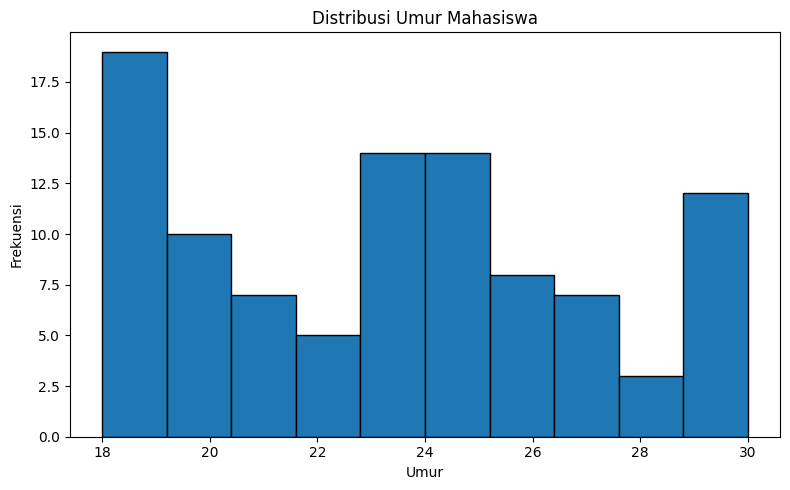

In [39]:
plt.figure(figsize=(8, 5))

plt.hist(df['Umur'], bins=10, edgecolor='black')

plt.title('Distribusi Umur Mahasiswa')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

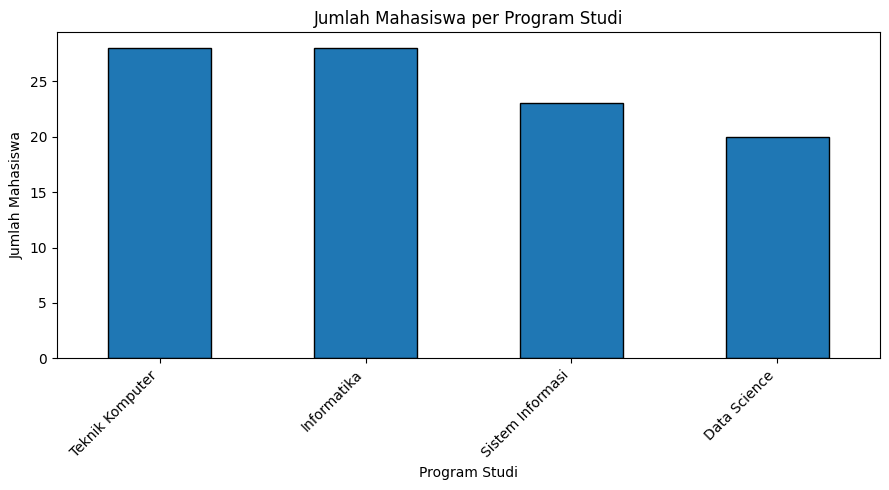

In [40]:
jumlah_prodi = df_asli['Prodi'].value_counts()

plt.figure(figsize=(9, 5))

jumlah_prodi.plot(kind='bar', edgecolor='black')

plt.title('Jumlah Mahasiswa per Program Studi')
plt.xlabel('Program Studi')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [41]:

df.to_csv('hasil_preprocessing.csv', index=False)


train_data.to_csv('data_latih.csv', index=False)
test_data.to_csv('data_uji.csv', index=False)

files.download('hasil_preprocessing.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>